<a href="https://colab.research.google.com/github/Sweper27/244107020175-Mesin-Learning/blob/main/Jobsheet5/Tugas(JS5).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
#Tugas
# Import library yang dibutuhkan
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import HDBSCAN
from sklearn.decomposition import PCA

# 1. Load Dataset Iris
iris = load_iris()
X = iris.data
y = iris.target
target_names = iris.target_names

print("Dataset berhasil dimuat!")
print(f"Jumlah sampel: {X.shape[0]}, Jumlah fitur: {X.shape[1]}")

Dataset berhasil dimuat!
Jumlah sampel: 150, Jumlah fitur: 4


In [5]:
# Standarisasi Fitur agar skala data seimbang
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Pemodelan HDBSCAN
# min_cluster_size=5 menentukan jumlah sampel minimum dalam satu cluster
hdb = HDBSCAN(min_cluster_size=5)
labels = hdb.fit_predict(X_scaled)

print("Proses clustering HDBSCAN selesai.")

Proses clustering HDBSCAN selesai.


In [6]:
# Menghitung jumlah cluster (tidak termasuk noise -1)
unique_labels = set(labels)
n_clusters = len(unique_labels) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print("="*40)
print(f"Hasil Clustering HDBSCAN:")
print(f"- Jumlah cluster terbentuk : {n_clusters}")
print(f"- Banyaknya noise (-1)     : {n_noise}")
print("="*40)

# Tabel Pemetaan (Crosstab) antara Label Asli vs Cluster HDBSCAN
df_res = pd.DataFrame({
    'Label Asli': [target_names[i] for i in y],
    'Cluster HDBSCAN': labels
})

print("\nTabel Pemetaan (Crosstab) Cluster vs Label Asli:")
print(pd.crosstab(df_res['Label Asli'], df_res['Cluster HDBSCAN']))

Hasil Clustering HDBSCAN:
- Jumlah cluster terbentuk : 2
- Banyaknya noise (-1)     : 2

Tabel Pemetaan (Crosstab) Cluster vs Label Asli:
Cluster HDBSCAN  -1   0   1
Label Asli                 
setosa            0  50   0
versicolor        0   0  50
virginica         2   0  48


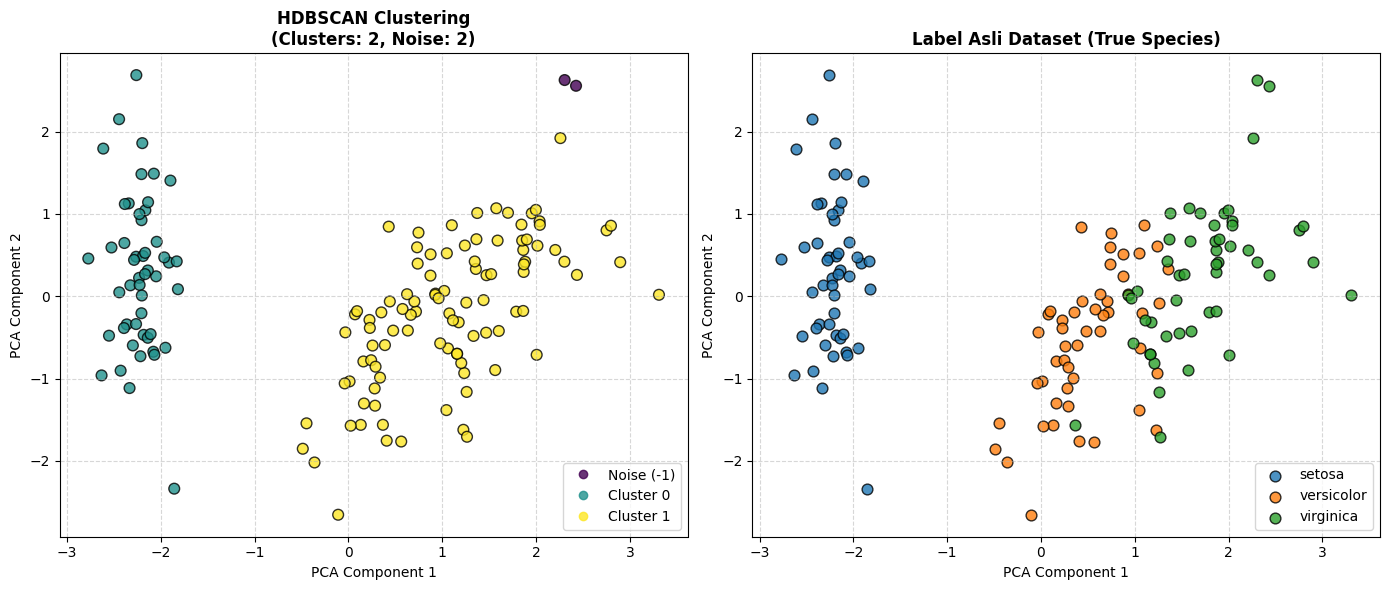

In [7]:
# Reduksi dimensi ke 2D menggunakan PCA untuk visualisasi
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Membuat plot perbandingan side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Hasil Clustering HDBSCAN
scatter0 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis', s=60, edgecolors='k', alpha=0.8)
axes[0].set_title(f"HDBSCAN Clustering\n(Clusters: {n_clusters}, Noise: {n_noise})", fontsize=12, fontweight='bold')
axes[0].set_xlabel("PCA Component 1")
axes[0].set_ylabel("PCA Component 2")
axes[0].grid(True, linestyle='--', alpha=0.5)

# Legend untuk Plot HDBSCAN
handles, _ = scatter0.legend_elements()
legend_labels = [f"Cluster {l}" if l != -1 else "Noise (-1)" for l in sorted(list(unique_labels))]
axes[0].legend(handles, legend_labels, loc='best')

# Plot 2: Label Asli (Ground Truth)
colors_true = ['#1f77b4', '#ff7f0e', '#2ca02c']
for i, name in enumerate(target_names):
    axes[1].scatter(X_pca[y == i, 0], X_pca[y == i, 1], label=name, color=colors_true[i], s=60, edgecolors='k', alpha=0.8)

axes[1].set_title("Label Asli Dataset (True Species)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("PCA Component 1")
axes[1].set_ylabel("PCA Component 2")
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(loc='best')

plt.tight_layout()
plt.show()